In [ ]:
!nvidia-smi

Tue Nov 24 21:19:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install numba -q
import numpy as np
from numba import cuda
import time
n = 10_000_000
a = np.random.rand(n).astype(np.float32)
b = np.random.rand(n).astype(np.float32)

start = time.time()
c_cpu = a + b
end = time.time()

print("CPU time:", end - start, "seconds")

CPU time: 0.015769243240356445 seconds


In [ ]:
a_gpu = cuda.to_device(a)
b_gpu = cuda.to_device(b)
c_gpu = cuda.device_array_like(a_gpu)

@cuda.jit
def add_kernel(a, b, c):
    i = cuda.grid(1)
    if i < a.size:
        c[i] = a[i] + b[i]

threads_per_block = 256
blocks_per_grid = (n + threads_per_block - 1) // threads_per_block


add_kernel[blocks_per_grid, threads_per_block](a_gpu, b_gpu, c_gpu)
cuda.synchronize()

start = time.time()
add_kernel[blocks_per_grid, threads_per_block](a_gpu, b_gpu, c_gpu)
cuda.synchronize()
end = time.time()

print("GPU time:", end - start, "seconds")

GPU time: 0.0007998943328857422 seconds


Image shape: (260, 194, 3)


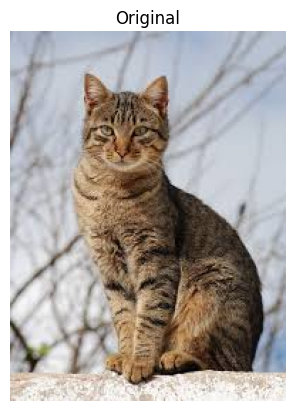

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open("images.jpg").convert("RGB")
img_array = np.array(img).astype(np.float32) / 255.0

print("Image shape:", img_array.shape)
plt.imshow(img)
plt.title("Original")
plt.axis("off")
plt.show()

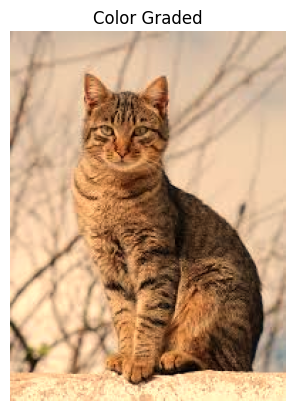

In [ ]:
color_matrix = np.array([
    [1.2, 0.0, 0.0],
    [0.0, 1.0, 0.0],
    [0.0, 0.0, 0.8]
], dtype=np.float32)

graded = img_array @ color_matrix.T
graded = np.clip(graded, 0, 1)

plt.imshow(graded)
plt.title("Color Graded")
plt.axis("off")
plt.show()

In [ ]:
from numba import cuda
import numpy as np
import time

@cuda.jit
def grade_kernel(img, matrix, out):
    x, y = cuda.grid(2)
    if x < img.shape[0] and y < img.shape[1]:
        r = img[x, y, 0]
        g = img[x, y, 1]
        b = img[x, y, 2]
        out[x, y, 0] = r * matrix[0, 0] + g * matrix[0, 1] + b * matrix[0, 2]
        out[x, y, 1] = r * matrix[1, 0] + g * matrix[1, 1] + b * matrix[1, 2]
        out[x, y, 2] = r * matrix[2, 0] + g * matrix[2, 1] + b * matrix[2, 2]

CPU time: 1.113 ms
GPU time: 0.418 ms
Speedup: 2.66x


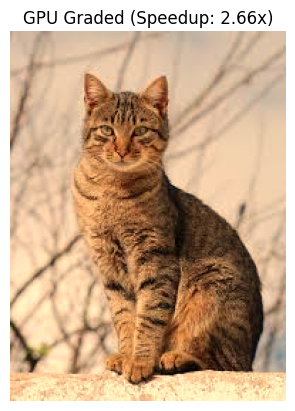

In [ ]:
#prepare data on the GPU
img_gpu = cuda.to_device(img_array)
matrix_gpu = cuda.to_device(color_matrix)
out_gpu = cuda.device_array_like(img_gpu)

height, width, _ = img_array.shape
threads_per_block = (16, 16)
blocks_per_grid_x = (height + threads_per_block[0] - 1) // threads_per_block[0]
blocks_per_grid_y = (width + threads_per_block[1] - 1) // threads_per_block[1]
blocks_per_grid = (blocks_per_grid_x, blocks_per_grid_y)

#compilation happens here
grade_kernel[blocks_per_grid, threads_per_block](img_gpu, matrix_gpu, out_gpu)
cuda.synchronize()

#real timed GPU run
start = time.time()
grade_kernel[blocks_per_grid, threads_per_block](img_gpu, matrix_gpu, out_gpu)
cuda.synchronize()
gpu_time = time.time() - start

#real timed CPU run
start = time.time()
graded_cpu = img_array @ color_matrix.T
graded_cpu = np.clip(graded_cpu, 0, 1)
cpu_time = time.time() - start

print(f"CPU time: {cpu_time*1000:.3f} ms")
print(f"GPU time: {gpu_time*1000:.3f} ms")
print(f"Speedup: {cpu_time/gpu_time:.2f}x")


result = out_gpu.copy_to_host()
result = np.clip(result, 0, 1)
plt.imshow(result)
plt.title(f"GPU Graded (Speedup: {cpu_time/gpu_time:.2f}x)")
plt.axis("off")
plt.show()

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 168MB/s]


Found 1 cat(s)


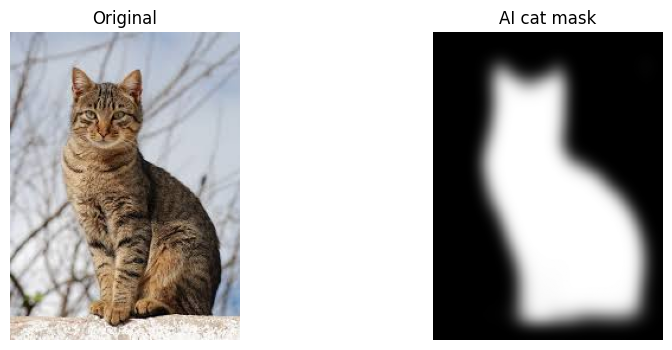

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from PIL import Image
from numba import cuda

img = Image.open("images.jpg").convert("RGB")
img_array = np.array(img).astype(np.float32) / 255.0
height, width, _ = img_array.shape

#GPU launch configuration
img_gpu = cuda.to_device(img_array)
threads_per_block = (16, 16)
blocks_per_grid = (
    (height + threads_per_block[0] - 1) // threads_per_block[0],
    (width + threads_per_block[1] - 1) // threads_per_block[1],
)


color_matrix = np.array([[1.2, 0.0, 0.0],
                         [0.0, 1.0, 0.0],
                         [0.0, 0.0, 0.8]], dtype=np.float32)
result = np.clip(img_array @ color_matrix.T, 0, 1)

import torch, torch.nn.functional as F
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import gaussian_blur

device = "cuda" if torch.cuda.is_available() else "cpu"
model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT).to(device).eval()
CAT_ID = 17

# Default-size handling
MAX_SIDE = 800
scale = min(1.0, MAX_SIDE / max(height, width))
small_h, small_w = int(height * scale), int(width * scale)

tensor = torch.from_numpy(img_array).permute(2, 0, 1).unsqueeze(0).to(device)
small = F.interpolate(tensor, size=(small_h, small_w), mode="bilinear", align_corners=False)

with torch.no_grad():
    pred = model([small[0]])[0]

cat_masks = [pred["masks"][i, 0] for i in range(len(pred["labels"]))
             if pred["labels"][i].item() == CAT_ID and pred["scores"][i].item() > 0.7]

if cat_masks:
    mask_small = torch.stack(cat_masks).max(dim=0).values
    print(f"Found {len(cat_masks)} cat(s)")
else:
    mask_small = torch.zeros(small_h, small_w, device=device)
    print("No cat found, edits will apply to the whole image as background")


mask_full = F.interpolate(mask_small[None, None], size=(height, width), mode="bilinear", align_corners=False)
mask_full = gaussian_blur(mask_full, kernel_size=31)[0, 0]
mask_np = mask_full.clamp(0, 1).cpu().numpy().astype(np.float32)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img);                      plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(mask_np, cmap="gray");     plt.title("AI cat mask"); plt.axis("off")
plt.show()

In [ ]:
lum_map = 0.2126 * img_array[..., 0] + 0.7152 * img_array[..., 1] + 0.0722 * img_array[..., 2]

def region_mean(weight):
    return float((lum_map * weight).sum() / (weight.sum() + 1e-6))

cat_lum = region_mean(mask_np) if mask_np.sum() > 1 else region_mean(np.ones_like(mask_np))
bg_lum  = region_mean(1 - mask_np)
print(f"Cat brightness: {cat_lum:.3f} | Background brightness: {bg_lum:.3f}")


cat_ev = float(np.clip(np.log2(0.45 / max(cat_lum, 1e-3)), -1.5, 1.5))
bg_ev  = float(np.clip(np.log2(0.40 / max(bg_lum,  1e-3)), -1.0, 1.0)) - 0.15

subject_params    = np.array([cat_ev, 0.15, -0.20, 0.25, 0.20,  0.05], dtype=np.float32)
background_params = np.array([bg_ev,  0.05, -0.10, 0.10, -0.15, -0.03], dtype=np.float32)
print("Subject params:", subject_params)
print("Background params:", background_params)

Cat brightness: 0.400 | Background brightness: 0.737
Subject params: [ 0.16917941  0.15       -0.2         0.25        0.2         0.05      ]
Background params: [-1.0313243  0.05      -0.1        0.1       -0.15      -0.03     ]


In [ ]:
#Lightroom-style GPU edit
import math

@cuda.jit(device=True)
def edit_pixel(r, g, b, p):
    # Exposure
    gain = 2.0 ** p[0]
    r *= gain; g *= gain; b *= gain

    # White balance / temperature
    r *= 1.0 + p[5]; b *= 1.0 - p[5]

    # Highlights & shadows weighted by brightness
    lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
    lum = min(max(lum, 0.0), 1.0)
    lift = p[3] * (1.0 - lum) ** 2 * 0.5 + p[2] * lum ** 2 * 0.5
    r += lift; g += lift; b += lift

    # Contrast around mid-grey
    k = 1.0 + p[1]
    r = (r - 0.5) * k + 0.5
    g = (g - 0.5) * k + 0.5
    b = (b - 0.5) * k + 0.5

    # Saturation
    l2 = 0.2126 * r + 0.7152 * g + 0.0722 * b
    s = 1.0 + p[4]
    r = l2 + (r - l2) * s
    g = l2 + (g - l2) * s
    b = l2 + (b - l2) * s
    return min(max(r, 0.0), 1.0), min(max(g, 0.0), 1.0), min(max(b, 0.0), 1.0)

@cuda.jit
def lightroom_kernel(img, mask, p_subject, p_bg, vignette, out):
    i, j = cuda.grid(2)
    h, w = img.shape[0], img.shape[1]
    if i < h and j < w:
        r, g, b = img[i, j, 0], img[i, j, 1], img[i, j, 2]
        sr, sg, sb = edit_pixel(r, g, b, p_subject)
        br, bg_, bb = edit_pixel(r, g, b, p_bg)
        m = mask[i, j]
        r = sr * m + br * (1.0 - m)
        g = sg * m + bg_ * (1.0 - m)
        b = sb * m + bb * (1.0 - m)

        # Vignette: darken edges
        dy = (i - h / 2.0) / (h / 2.0)
        dx = (j - w / 2.0) / (w / 2.0)
        v = 1.0 - vignette * (dx * dx + dy * dy) * 0.5
        out[i, j, 0] = r * v
        out[i, j, 1] = g * v
        out[i, j, 2] = b * v

@cuda.jit
def sharpen_kernel(src, mask, amount_subject, amount_bg, out):
    # Unsharp mask using a 3x3 box blur; cat gets more sharpening than background
    i, j = cuda.grid(2)
    h, w = src.shape[0], src.shape[1]
    if i < h and j < w:
        amt = amount_subject * mask[i, j] + amount_bg * (1.0 - mask[i, j])
        for c in range(3):
            total = 0.0
            for di in range(-1, 2):
                for dj in range(-1, 2):
                    ii = min(max(i + di, 0), h - 1)
                    jj = min(max(j + dj, 0), w - 1)
                    total += src[ii, jj, c]
            blur = total / 9.0
            val = src[i, j, c] + amt * (src[i, j, c] - blur)
            out[i, j, c] = min(max(val, 0.0), 1.0)

# Upload and run
mask_gpu = cuda.to_device(mask_np)
ps_gpu   = cuda.to_device(subject_params)
pb_gpu   = cuda.to_device(background_params)
edited_gpu  = cuda.device_array_like(img_gpu)
sharpen_gpu = cuda.device_array_like(img_gpu)

def run_pipeline():
    lightroom_kernel[blocks_per_grid, threads_per_block](img_gpu, mask_gpu, ps_gpu, pb_gpu, np.float32(0.35), edited_gpu)
    sharpen_kernel[blocks_per_grid, threads_per_block](edited_gpu, mask_gpu, np.float32(0.8), np.float32(0.2), sharpen_gpu)

run_pipeline(); cuda.synchronize()          #compile

start = time.time()
run_pipeline(); cuda.synchronize()
pipeline_gpu_time = time.time() - start
print(f"Full AI-edit pipeline on GPU: {pipeline_gpu_time*1000:.3f} ms")

Full AI-edit pipeline on GPU: 0.713 ms


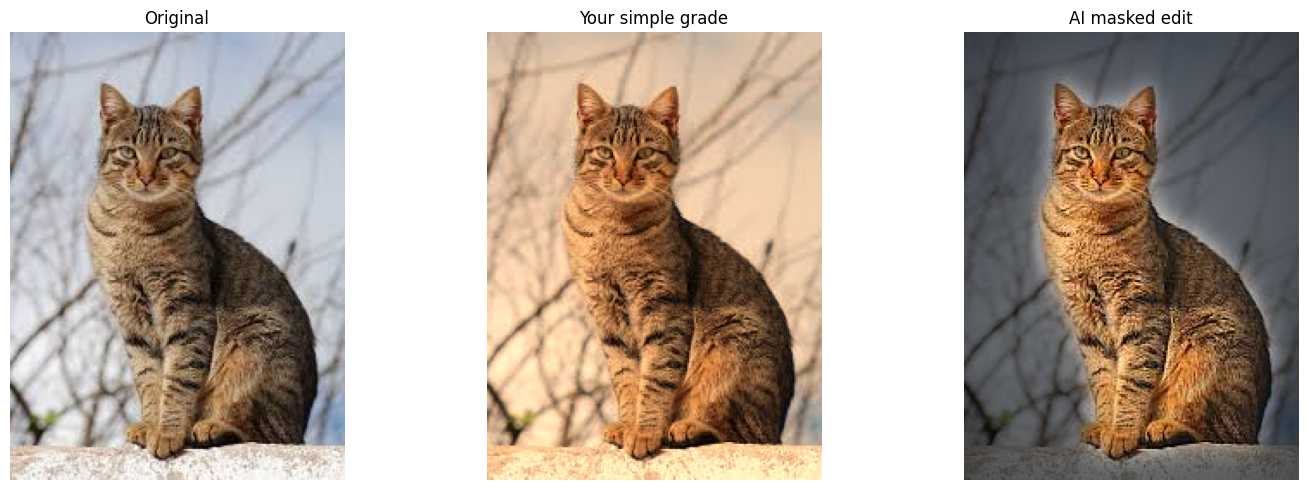

In [ ]:
#Comparision
final = sharpen_gpu.copy_to_host()

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(img_array);   plt.title("Original");           plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(result);      plt.title("Your simple grade");  plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(final);       plt.title("AI masked edit");     plt.axis("off")
plt.tight_layout(); plt.show()

Loaded images.jpg: 194x260, device = cuda
Mask R-CNN  CPU 4982 ms | GPU 159 ms | 31.4x
Found 1 cat(s)
--- 0.25 MP (431x578) ---
  raw    CPU       2.0 ms | GPU       2.3 ms |   0.86x
  edited CPU      43.7 ms | GPU      10.4 ms |   4.18x (kernels only 2.7 ms)
  CPU vs GPU output: PSNR 141.2 dB, SSIM 1.0000
--- 1 MP (863x1157) ---
  raw    CPU       8.8 ms | GPU       6.5 ms |   1.35x
  edited CPU     204.9 ms | GPU      33.0 ms |   6.20x (kernels only 10.3 ms)
  CPU vs GPU output: PSNR 141.5 dB, SSIM 1.0000
--- 4 MP (1727x2315) ---
  raw    CPU      47.2 ms | GPU      32.7 ms |   1.44x
  edited CPU    1248.3 ms | GPU     196.4 ms |   6.36x (kernels only 25.2 ms)
  CPU vs GPU output: PSNR 141.3 dB, SSIM 1.0000
--- 8 MP (2443x3274) ---
  raw    CPU      93.2 ms | GPU      59.1 ms |   1.58x
  edited CPU    2570.3 ms | GPU     322.0 ms |   7.98x (kernels only 34.2 ms)
  CPU vs GPU output: PSNR 142.0 dB, SSIM nan

  megapixels  width  height  raw_cpu_ms  raw_gpu_ms  edited_cpu_ms  edited_gp

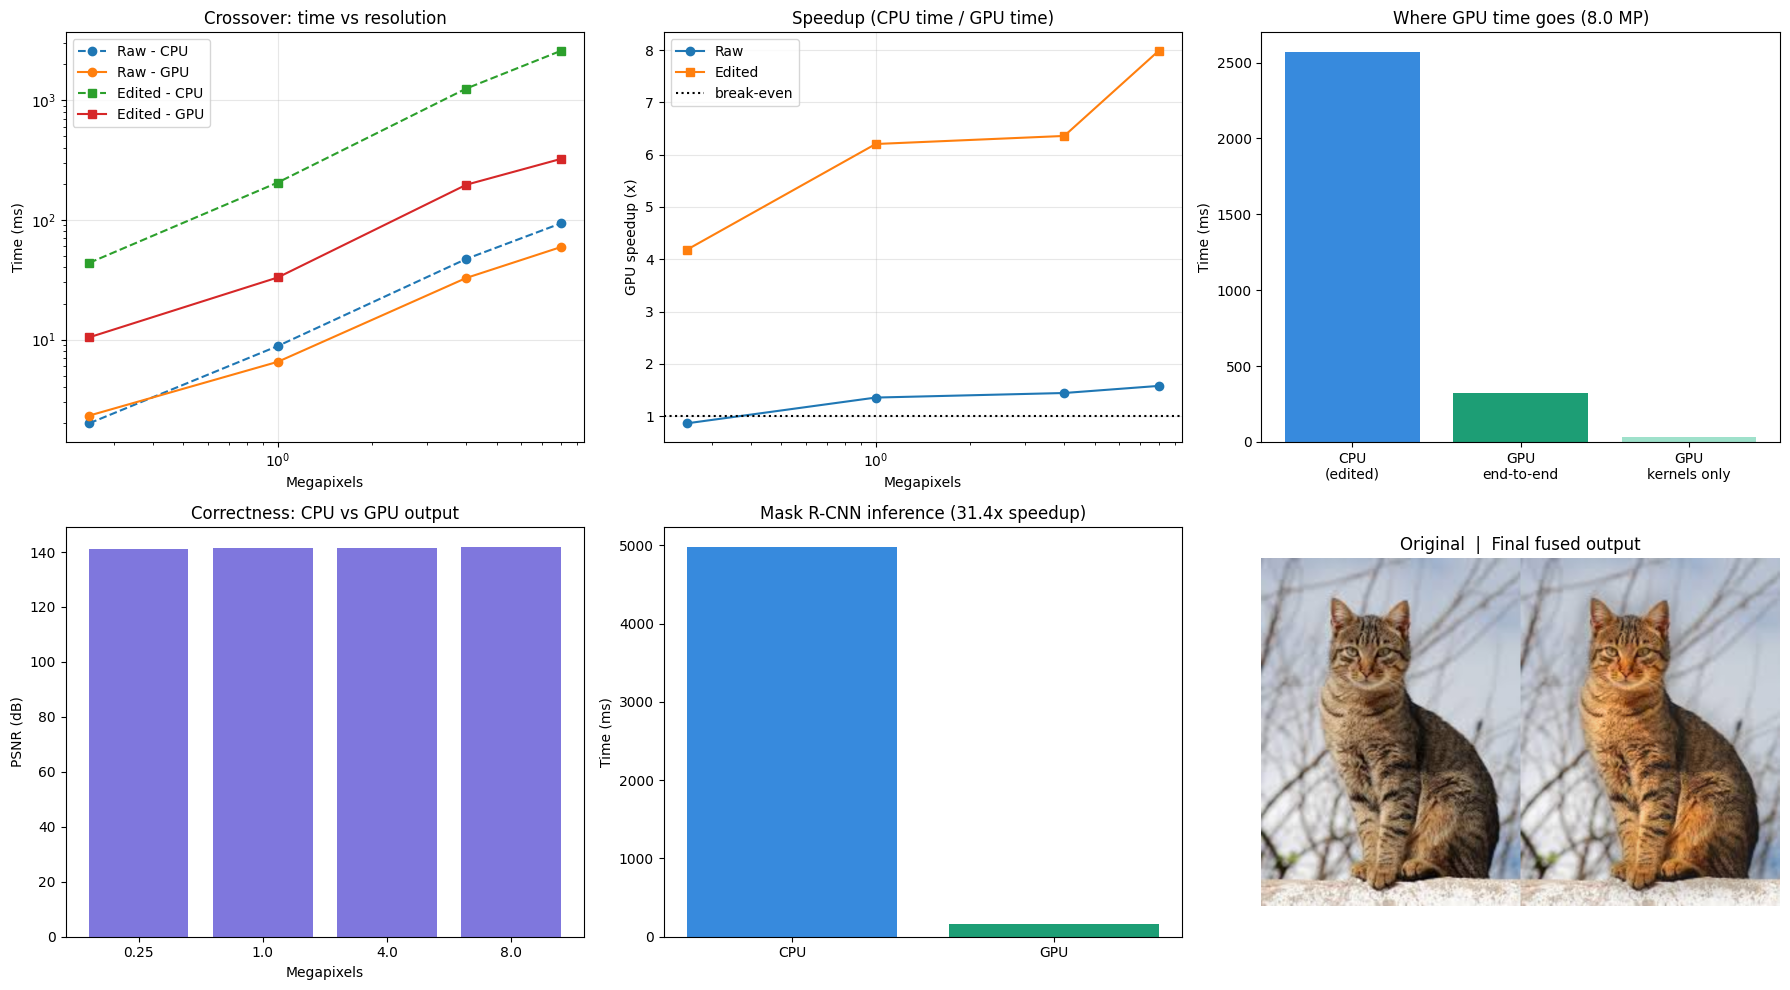

Saved results.csv and dashboard.png (see the Colab file sidebar)


In [ ]:
# ===== ALL-IN-ONE FINAL CELL: nothing from earlier cells is needed =====
import cv2, math, time, gc
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn.functional as F
from PIL import Image
from numba import cuda
from scipy.ndimage import uniform_filter
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import gaussian_blur
from skimage.metrics import peak_signal_noise_ratio as psnr_fn
from skimage.metrics import structural_similarity as ssim_fn

IMAGE_FILE = "images.jpg"
MEGAPIXELS = [0.25, 1, 4, 8]      # if you hit an out-of-memory error, remove 8
TPB = (16, 16)
device = "cuda" if torch.cuda.is_available() else "cpu"

def sync():
    cuda.synchronize()
    if device == "cuda": torch.cuda.synchronize()

def bench(fn, repeats, warmup=True):
    """Median time in ms. Warmup discarded (GPU compile), sync before stopping the clock."""
    if warmup: fn(); sync()
    ts, out = [], None
    for _ in range(repeats):
        t = time.perf_counter(); out = fn(); sync()
        ts.append(time.perf_counter() - t)
    return float(np.median(ts)) * 1000, out

def grid_for(h, w):
    return ((h + TPB[0] - 1) // TPB[0], (w + TPB[1] - 1) // TPB[1])

# ---------- 1. Load image ----------
img_array = np.array(Image.open(IMAGE_FILE).convert("RGB")).astype(np.float32) / 255.0
H0, W0 = img_array.shape[:2]
print(f"Loaded {IMAGE_FILE}: {W0}x{H0}, device = {device}")

color_matrix = np.array([[1.2, 0, 0], [0, 1.0, 0], [0, 0, 0.8]], dtype=np.float32)

# ---------- 2. AI mask (Mask R-CNN) + CPU vs GPU timing of the model ----------
model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT).eval()
scale = min(1.0, 800 / max(H0, W0))
sh, sw = int(H0 * scale), int(W0 * scale)
tensor = torch.from_numpy(img_array).permute(2, 0, 1).unsqueeze(0)
small = F.interpolate(tensor, size=(sh, sw), mode="bilinear", align_corners=False)

def detect(dev):
    model.to(dev); x = small[0].to(dev)
    with torch.no_grad():
        model([x]);
        if dev == "cuda": torch.cuda.synchronize()
        t = time.perf_counter(); pred = model([x])[0]
        if dev == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) * 1000, pred

gpu_detect_ms, pred = detect("cuda") if device == "cuda" else (None, None)
cpu_detect_ms, pred_cpu = detect("cpu")
if pred is None: pred = pred_cpu
pred = {k: v.cpu() for k, v in pred.items()}
print(f"Mask R-CNN  CPU {cpu_detect_ms:.0f} ms" + (f" | GPU {gpu_detect_ms:.0f} ms | {cpu_detect_ms/gpu_detect_ms:.1f}x" if gpu_detect_ms else ""))

CAT_ID = 17
cats = [pred["masks"][i, 0] for i in range(len(pred["labels"]))
        if pred["labels"][i].item() == CAT_ID and pred["scores"][i].item() > 0.7]
if cats:
    m_small = torch.stack(cats).max(dim=0).values
    print(f"Found {len(cats)} cat(s)")
else:
    m_small = torch.zeros(sh, sw)
    print("No cat found: the whole image is treated as background")
m_full = F.interpolate(m_small[None, None], size=(H0, W0), mode="bilinear", align_corners=False)
m_full = gaussian_blur(m_full, kernel_size=31)[0, 0]
mask_np = np.ascontiguousarray(m_full.clamp(0, 1).numpy().astype(np.float32))
del model; gc.collect()
if device == "cuda": torch.cuda.empty_cache()

# ---------- 3. Auto-analysis -> edit parameters ----------
lum_map = 0.2126 * img_array[..., 0] + 0.7152 * img_array[..., 1] + 0.0722 * img_array[..., 2]
def region_mean(w): return float((lum_map * w).sum() / (w.sum() + 1e-6))
cat_lum = region_mean(mask_np) if mask_np.sum() > 1 else region_mean(np.ones_like(mask_np))
bg_lum = region_mean(1 - mask_np)
cat_ev = float(np.clip(np.log2(0.45 / max(cat_lum, 1e-3)), -1.5, 1.5))
bg_ev = float(np.clip(np.log2(0.40 / max(bg_lum, 1e-3)), -1.0, 1.0)) - 0.15
subject_params = np.array([cat_ev, 0.15, -0.20, 0.25, 0.20, 0.05], dtype=np.float32)
background_params = np.array([bg_ev, 0.05, -0.10, 0.10, -0.15, -0.03], dtype=np.float32)

# ---------- 4. GPU kernels ----------
@cuda.jit(device=True)
def edit_pixel(r, g, b, p):
    gain = 2.0 ** p[0]
    r *= gain; g *= gain; b *= gain
    r *= 1.0 + p[5]; b *= 1.0 - p[5]
    lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
    lum = min(max(lum, 0.0), 1.0)
    lift = p[3] * (1.0 - lum) ** 2 * 0.5 + p[2] * lum ** 2 * 0.5
    r += lift; g += lift; b += lift
    k = 1.0 + p[1]
    r = (r - 0.5) * k + 0.5; g = (g - 0.5) * k + 0.5; b = (b - 0.5) * k + 0.5
    l2 = 0.2126 * r + 0.7152 * g + 0.0722 * b
    s = 1.0 + p[4]
    r = l2 + (r - l2) * s; g = l2 + (g - l2) * s; b = l2 + (b - l2) * s
    return min(max(r, 0.0), 1.0), min(max(g, 0.0), 1.0), min(max(b, 0.0), 1.0)

@cuda.jit
def lightroom_kernel(img, mask, p_subject, p_bg, vignette, out):
    i, j = cuda.grid(2)
    h, w = img.shape[0], img.shape[1]
    if i < h and j < w:
        r, g, b = img[i, j, 0], img[i, j, 1], img[i, j, 2]
        sr, sg, sb = edit_pixel(r, g, b, p_subject)
        br, bg_, bb = edit_pixel(r, g, b, p_bg)
        m = mask[i, j]
        r = sr * m + br * (1.0 - m); g = sg * m + bg_ * (1.0 - m); b = sb * m + bb * (1.0 - m)
        dy = (i - h / 2.0) / (h / 2.0); dx = (j - w / 2.0) / (w / 2.0)
        v = 1.0 - vignette * (dx * dx + dy * dy) * 0.5
        out[i, j, 0] = r * v; out[i, j, 1] = g * v; out[i, j, 2] = b * v

@cuda.jit
def sharpen_kernel(src, mask, amt_s, amt_b, out):
    i, j = cuda.grid(2)
    h, w = src.shape[0], src.shape[1]
    if i < h and j < w:
        amt = amt_s * mask[i, j] + amt_b * (1.0 - mask[i, j])
        for c in range(3):
            total = 0.0
            for di in range(-1, 2):
                for dj in range(-1, 2):
                    ii = min(max(i + di, 0), h - 1); jj = min(max(j + dj, 0), w - 1)
                    total += src[ii, jj, c]
            val = src[i, j, c] + amt * (src[i, j, c] - total / 9.0)
            out[i, j, c] = min(max(val, 0.0), 1.0)

@cuda.jit
def raw_grade_kernel(img, m, out):
    i, j = cuda.grid(2)
    if i < img.shape[0] and j < img.shape[1]:
        r, g, b = img[i, j, 0], img[i, j, 1], img[i, j, 2]
        for c in range(3):
            out[i, j, c] = min(max(r * m[c, 0] + g * m[c, 1] + b * m[c, 2], 0.0), 1.0)

ps_d, pb_d, cm_d = (cuda.to_device(a) for a in (subject_params, background_params, color_matrix))

# ---------- 5. CPU equivalents ----------
def edit_cpu(img, p):
    r, g, b = img[..., 0].copy(), img[..., 1].copy(), img[..., 2].copy()
    gain = 2.0 ** p[0]
    r *= gain; g *= gain; b *= gain
    r *= 1.0 + p[5]; b *= 1.0 - p[5]
    lum = np.clip(0.2126 * r + 0.7152 * g + 0.0722 * b, 0, 1)
    lift = p[3] * (1 - lum) ** 2 * 0.5 + p[2] * lum ** 2 * 0.5
    r += lift; g += lift; b += lift
    k = 1.0 + p[1]
    r = (r - 0.5) * k + 0.5; g = (g - 0.5) * k + 0.5; b = (b - 0.5) * k + 0.5
    l2 = 0.2126 * r + 0.7152 * g + 0.0722 * b
    s = 1.0 + p[4]
    r = l2 + (r - l2) * s; g = l2 + (g - l2) * s; b = l2 + (b - l2) * s
    return np.clip(np.stack([r, g, b], axis=-1), 0, 1).astype(np.float32)

def sharpen_cpu(src, mask, a_s, a_b):
    blur = uniform_filter(src, size=(3, 3, 1), mode="nearest")
    amt = a_s * mask[..., None] + a_b * (1 - mask[..., None])
    return np.clip(src + amt * (src - blur), 0, 1).astype(np.float32)

# ---------- 6. Pyramid fusion: CPU (OpenCV) and GPU (PyTorch) ----------
def pyr_sizes(h, w, levels):
    s = [(h, w)]
    for _ in range(levels):
        h, w = max(1, h // 2), max(1, w // 2); s.append((h, w))
    return s

def pyramid_blend(a, b, mask, levels=5):
    h, w = a.shape[:2]; sizes = pyr_sizes(h, w, levels)
    m3 = np.repeat(mask[..., None], 3, axis=2).astype(np.float32)
    def gp(x):
        p = [x.astype(np.float32)]
        for (hh, ww) in sizes[1:]: p.append(cv2.resize(p[-1], (ww, hh), interpolation=cv2.INTER_LINEAR))
        return p
    def lp(g):
        out = [g[-1]]
        for i in range(len(g) - 1, 0, -1):
            hh, ww = sizes[i - 1]
            out.append(g[i - 1] - cv2.resize(g[i], (ww, hh), interpolation=cv2.INTER_LINEAR))
        return out
    lA, lB, gM = lp(gp(a)), lp(gp(b)), gp(m3)[::-1]
    bl = [x * m + y * (1 - m) for x, y, m in zip(lA, lB, gM)]
    res = bl[0]
    for i in range(1, len(bl)):
        hh, ww = sizes[levels - i]
        res = cv2.resize(res, (ww, hh), interpolation=cv2.INTER_LINEAR) + bl[i]
    return np.clip(res, 0, 1)

def pyramid_blend_gpu(a_np, b_np, mask_, levels, dev):
    h, w = a_np.shape[:2]; sizes = pyr_sizes(h, w, levels)
    tt = lambda x: torch.from_numpy(x).permute(2, 0, 1).unsqueeze(0).float().to(dev)
    a_t, b_t = tt(a_np), tt(b_np)
    m_t = torch.from_numpy(mask_).unsqueeze(0).unsqueeze(0).repeat(1, 3, 1, 1).float().to(dev)
    def gp(x):
        p = [x]
        for (hh, ww) in sizes[1:]: p.append(F.interpolate(p[-1], size=(hh, ww), mode="bilinear", align_corners=False))
        return p
    def lp(g):
        out = [g[-1]]
        for i in range(len(g) - 1, 0, -1):
            out.append(g[i - 1] - F.interpolate(g[i], size=sizes[i - 1], mode="bilinear", align_corners=False))
        return out
    lA, lB, gM = lp(gp(a_t)), lp(gp(b_t)), gp(m_t)[::-1]
    bl = [x * m + y * (1 - m) for x, y, m in zip(lA, lB, gM)]
    res = bl[0]
    for i in range(1, len(bl)):
        res = F.interpolate(res, size=sizes[levels - i], mode="bilinear", align_corners=False) + bl[i]
    return res.clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy()

# ---------- 7. Raw and Edited workloads ----------
def raw_cpu(img): return np.clip(img @ color_matrix.T, 0, 1)

def raw_gpu(img):                                   # includes upload + download
    d = cuda.to_device(img); o = cuda.device_array_like(d)
    raw_grade_kernel[grid_for(*img.shape[:2]), TPB](d, cm_d, o)
    return o.copy_to_host()

def edited_cpu(img, mask):
    m = mask[..., None]
    e = edit_cpu(img, subject_params) * m + edit_cpu(img, background_params) * (1 - m)
    h, w = img.shape[:2]
    yy = (np.arange(h, dtype=np.float32) - h / 2) / (h / 2)
    xx = (np.arange(w, dtype=np.float32) - w / 2) / (w / 2)
    v = 1.0 - 0.35 * (yy[:, None] ** 2 + xx[None, :] ** 2) * 0.5
    e = (e * v[..., None]).astype(np.float32)
    return pyramid_blend(sharpen_cpu(e, mask, 0.8, 0.2), img, mask, 5)

def edit_kernels(d_img, d_mask, d_edit, d_sharp):   # data already on GPU
    g = grid_for(*d_img.shape[:2])
    lightroom_kernel[g, TPB](d_img, d_mask, ps_d, pb_d, np.float32(0.35), d_edit)
    sharpen_kernel[g, TPB](d_edit, d_mask, np.float32(0.8), np.float32(0.2), d_sharp)

def edited_gpu(img, mask):                          # upload + kernels + download + GPU fusion
    d_img, d_mask = cuda.to_device(img), cuda.to_device(mask)
    d_edit, d_sharp = cuda.device_array_like(d_img), cuda.device_array_like(d_img)
    edit_kernels(d_img, d_mask, d_edit, d_sharp)
    return pyramid_blend_gpu(d_sharp.copy_to_host(), img, mask, 5, device)

# ---------- 8. The sweep ----------
rows, hero = [], {}
for mp in MEGAPIXELS:
    s = math.sqrt(mp * 1e6 / (H0 * W0)); h, w = int(H0 * s), int(W0 * s)
    img = np.ascontiguousarray(cv2.resize(img_array, (w, h), interpolation=cv2.INTER_LINEAR), dtype=np.float32)
    mask = np.ascontiguousarray(np.clip(cv2.resize(mask_np, (w, h), interpolation=cv2.INTER_LINEAR), 0, 1), dtype=np.float32)
    print(f"--- {mp} MP ({w}x{h}) ---")

    raw_cpu_ms, raw_cpu_out = bench(lambda: raw_cpu(img), 3, warmup=False)
    raw_gpu_ms, raw_gpu_out = bench(lambda: raw_gpu(img), 5)
    ed_cpu_ms, ed_cpu_out = bench(lambda: edited_cpu(img, mask), 2, warmup=False)
    ed_gpu_ms, ed_gpu_out = bench(lambda: edited_gpu(img, mask), 3)

    d_img, d_mask = cuda.to_device(img), cuda.to_device(mask)
    d_edit, d_sharp = cuda.device_array_like(d_img), cuda.device_array_like(d_img)
    ker_ms, _ = bench(lambda: edit_kernels(d_img, d_mask, d_edit, d_sharp), 5)

    a, b = np.clip(ed_cpu_out, 0, 1), np.clip(ed_gpu_out, 0, 1)
    psnr = psnr_fn(a, b, data_range=1.0)
    ssim = ssim_fn(a, b, channel_axis=2, data_range=1.0) if mp <= 4 else np.nan
    rows.append(dict(megapixels=mp, width=w, height=h,
                     raw_cpu_ms=raw_cpu_ms, raw_gpu_ms=raw_gpu_ms,
                     edited_cpu_ms=ed_cpu_ms, edited_gpu_ms=ed_gpu_ms,
                     edited_gpu_kernels_only_ms=ker_ms,
                     raw_speedup=raw_cpu_ms / raw_gpu_ms, edited_speedup=ed_cpu_ms / ed_gpu_ms,
                     psnr_db=psnr, ssim=ssim,
                     raw_max_abs_err=float(np.abs(raw_cpu_out - raw_gpu_out).max())))
    print(f"  raw    CPU {raw_cpu_ms:9.1f} ms | GPU {raw_gpu_ms:9.1f} ms | {raw_cpu_ms/raw_gpu_ms:6.2f}x")
    print(f"  edited CPU {ed_cpu_ms:9.1f} ms | GPU {ed_gpu_ms:9.1f} ms | {ed_cpu_ms/ed_gpu_ms:6.2f}x (kernels only {ker_ms:.1f} ms)")
    print(f"  CPU vs GPU output: PSNR {psnr:.1f} dB, SSIM {ssim:.4f}")
    if not hero or mp == 1: hero = dict(orig=img.copy(), out=b.copy())
    del img, mask, d_img, d_mask, d_edit, d_sharp, raw_cpu_out, raw_gpu_out, ed_cpu_out, ed_gpu_out, a, b
    gc.collect()
    if device == "cuda": torch.cuda.empty_cache()

# ---------- 9. CSV + verdict ----------
df = pd.DataFrame(rows)
df.to_csv("results.csv", index=False)
print("\n", df.round(3).to_string(index=False))
for name, col in [("RAW", "raw_speedup"), ("EDITED", "edited_speedup")]:
    wins = df[df[col] > 1]
    if len(wins) == len(df): print(f"{name}: GPU faster at every size tested (crossover is below {df.megapixels.min()} MP on this CPU/GPU pair)")
    elif len(wins) == 0: print(f"{name}: CPU faster at every size tested")
    else: print(f"{name}: GPU overtakes CPU from {wins.megapixels.min()} MP")

# ---------- 10. Dashboard ----------
fig, ax = plt.subplots(2, 3, figsize=(18, 10)); x = df.megapixels
ax[0, 0].plot(x, df.raw_cpu_ms, "o--", label="Raw - CPU"); ax[0, 0].plot(x, df.raw_gpu_ms, "o-", label="Raw - GPU")
ax[0, 0].plot(x, df.edited_cpu_ms, "s--", label="Edited - CPU"); ax[0, 0].plot(x, df.edited_gpu_ms, "s-", label="Edited - GPU")
ax[0, 0].set(xscale="log", yscale="log", xlabel="Megapixels", ylabel="Time (ms)", title="Crossover: time vs resolution")
ax[0, 0].legend(); ax[0, 0].grid(alpha=0.3)

ax[0, 1].plot(x, df.raw_speedup, "o-", label="Raw"); ax[0, 1].plot(x, df.edited_speedup, "s-", label="Edited")
ax[0, 1].axhline(1, color="k", ls=":", label="break-even")
ax[0, 1].set(xscale="log", xlabel="Megapixels", ylabel="GPU speedup (x)", title="Speedup (CPU time / GPU time)")
ax[0, 1].legend(); ax[0, 1].grid(alpha=0.3)

last = df.iloc[-1]
ax[0, 2].bar(["CPU\n(edited)", "GPU\nend-to-end", "GPU\nkernels only"],
             [last.edited_cpu_ms, last.edited_gpu_ms, last.edited_gpu_kernels_only_ms],
             color=["#378ADD", "#1D9E75", "#9FE1CB"])
ax[0, 2].set(ylabel="Time (ms)", title=f"Where GPU time goes ({last.megapixels} MP)")

ax[1, 0].bar([str(m) for m in x], df.psnr_db, color="#7F77DD")
ax[1, 0].set(xlabel="Megapixels", ylabel="PSNR (dB)", title="Correctness: CPU vs GPU output")

if gpu_detect_ms:
    ax[1, 1].bar(["CPU", "GPU"], [cpu_detect_ms, gpu_detect_ms], color=["#378ADD", "#1D9E75"])
    ax[1, 1].set(ylabel="Time (ms)", title=f"Mask R-CNN inference ({cpu_detect_ms/gpu_detect_ms:.1f}x speedup)")
else:
    ax[1, 1].text(0.5, 0.5, "No GPU available", ha="center"); ax[1, 1].axis("off")

ax[1, 2].imshow(np.clip(np.concatenate([hero["orig"], hero["out"]], axis=1), 0, 1)); ax[1, 2].axis("off")
ax[1, 2].set_title("Original  |  Final fused output")
plt.tight_layout(); plt.savefig("dashboard.png", dpi=150); plt.show()
print("Saved results.csv and dashboard.png (see the Colab file sidebar)")

---
## 1. What we built: before and after

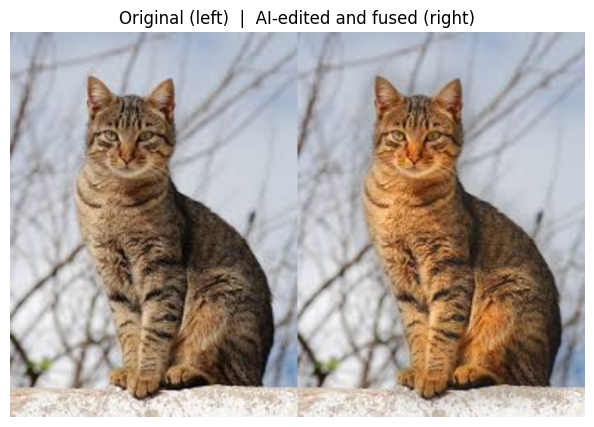

Source photo: 194x260 px (upscaled for the larger sizes). Mask R-CNN found 1 cat.


**Say:** The AI finds the cat, edits it separately from the background, sharpens, and blends it back with pyramid fusion.

---
## 2. Crossover: time vs image size

MP,Raw CPU (ms),Raw GPU (ms),Edited CPU (ms),Edited GPU (ms)
0.200000,2.000000,2.300000,43.700000,10.400000
1.000000,8.800000,6.500000,204.900000,33.000000
4.000000,47.200000,32.700000,1248.300000,196.400000
8.000000,93.200000,59.100000,2570.300000,322.000000


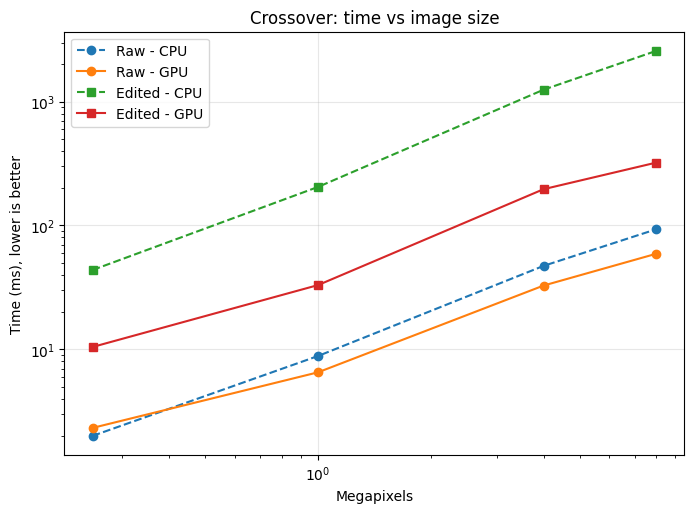

**Say:** Raw: CPU wins only at 0.25 MP, GPU takes over from 1 MP. Edited: GPU is faster at every size, so its crossover is below our smallest size.

---
## 3. Speedup (CPU time / GPU time)

MP,Raw speedup (x),Edited speedup (x)
0.250000,0.860000,4.180000
1.000000,1.350000,6.200000
4.000000,1.440000,6.360000
8.000000,1.580000,7.980000


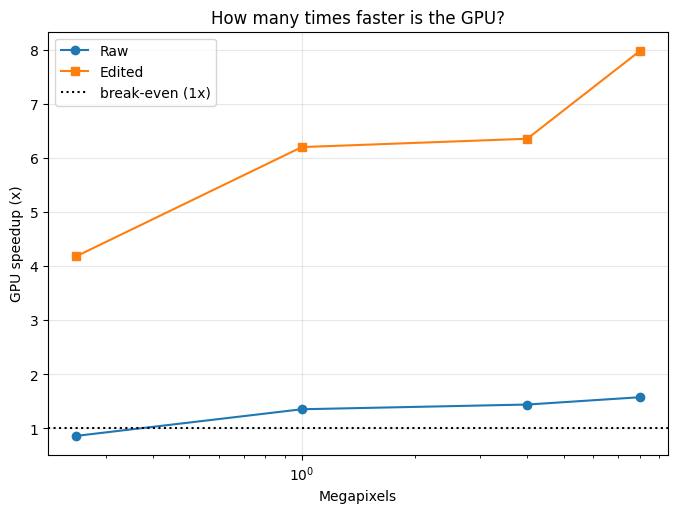

**Say:** Raw is the only case under 1x, and only at the smallest size. Edited grows from about 4x to 8x. The heavier the workload, the more the GPU wins.

---
## 4. Where the GPU time goes

MP,GPU end-to-end (ms),GPU kernels only (ms),Everything else (ms),Everything else (%)
0.200000,10.400000,2.700000,7.700000,74.100000
1.000000,33.000000,10.300000,22.700000,68.700000
4.000000,196.400000,25.200000,171.200000,87.200000
8.000000,322.000000,34.200000,287.800000,89.400000


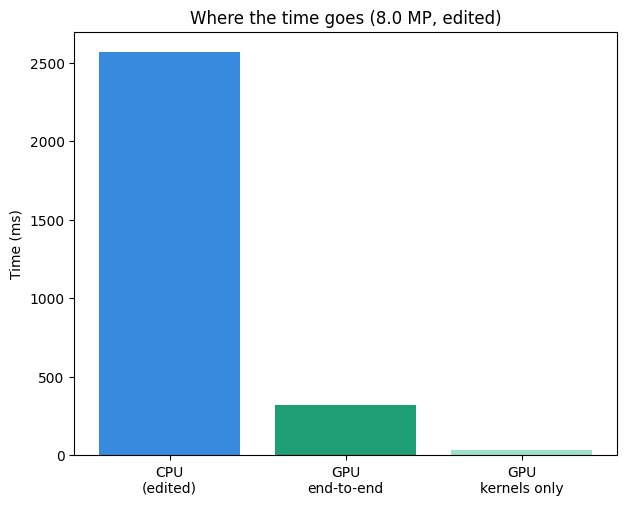

**Say:** At 8 MP the kernels take about 34 ms but the full pipeline takes about 322 ms. Most of the rest is data movement plus the PyTorch fusion step, so keeping data on the GPU would widen the gap.

---
## 5. Correctness: CPU output vs GPU output

MP,PSNR (dB),SSIM
0.250000,141.244300,1.000000
1.000000,141.516400,1.000000
4.000000,141.313100,1.000000
8.000000,141.958400,nan


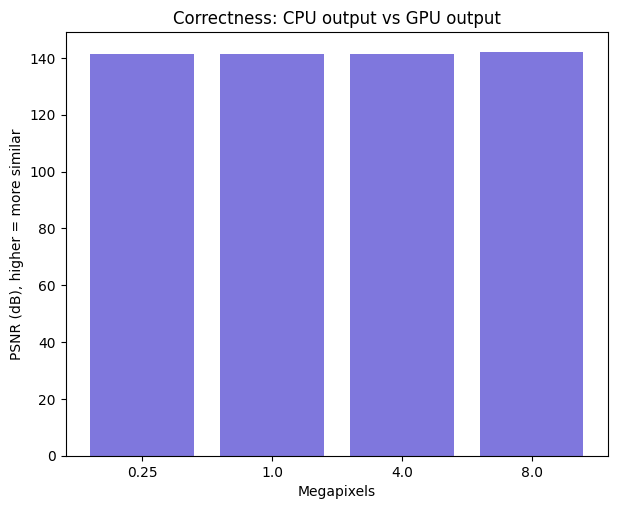

**Say:** Above about 40 dB the images look identical. Ours are around 141 dB with SSIM of 1.0, so CPU and GPU outputs match essentially exactly. SSIM is blank at 8 MP only because I skipped it there to save time.

---
## 6. The AI model: Mask R-CNN

Device,Time (ms)
CPU,4982
GPU,159


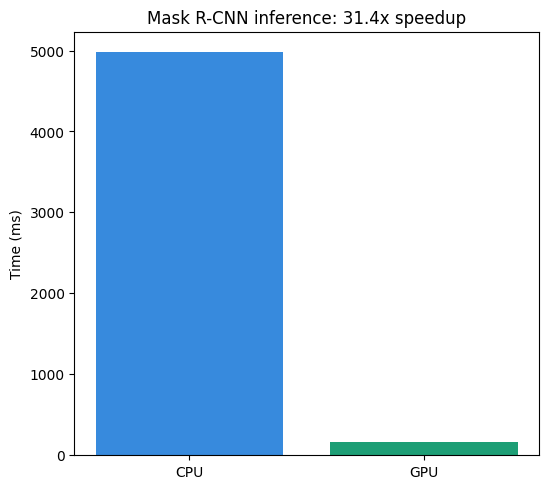

**Say:** The neural network is about 31x faster on GPU, versus 4x to 8x for our hand-written kernels, because it is mostly large matrix multiplications.


Saved PNGs: ['1_before_after.png', '2_crossover.png', '3_speedup.png', '4_gpu_time_breakdown.png', '5_correctness.png', '6_maskrcnn.png']


In [ ]:
# ===== PRESENTATION CELL: tables + charts in presenting order =====
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ---- recover data if the runtime was restarted ----
if 'df' not in globals():
    df = pd.read_csv("results.csv")
if 'cpu_detect_ms' not in globals():
    cpu_detect_ms, gpu_detect_ms = 4982.0, 159.0     # from your printed run
have_hero = 'hero' in globals()

def title(text):
    display(Markdown(f"---\n## {text}"))

def say(text):
    display(Markdown(f"**Say:** {text}"))

mp = df.megapixels

# ---------- 1. Before / after ----------
title("1. What we built: before and after")
if have_hero:
    plt.figure(figsize=(10, 5))
    plt.imshow(np.clip(np.concatenate([hero["orig"], hero["out"]], axis=1), 0, 1))
    plt.axis("off"); plt.title("Original (left)  |  AI-edited and fused (right)")
    plt.savefig("1_before_after.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print("Before/after image not in memory (needs the earlier run). Use dashboard.png instead.")
print("Source photo: 194x260 px (upscaled for the larger sizes). Mask R-CNN found 1 cat.")
say("The AI finds the cat, edits it separately from the background, sharpens, and blends it back with pyramid fusion.")

# ---------- 2. Crossover ----------
title("2. Crossover: time vs image size")
t2 = df[["megapixels", "raw_cpu_ms", "raw_gpu_ms", "edited_cpu_ms", "edited_gpu_ms"]].round(1)
t2.columns = ["MP", "Raw CPU (ms)", "Raw GPU (ms)", "Edited CPU (ms)", "Edited GPU (ms)"]
display(t2.style.hide(axis="index"))
plt.figure(figsize=(8, 5.5))
plt.plot(mp, df.raw_cpu_ms, "o--", label="Raw - CPU");     plt.plot(mp, df.raw_gpu_ms, "o-", label="Raw - GPU")
plt.plot(mp, df.edited_cpu_ms, "s--", label="Edited - CPU"); plt.plot(mp, df.edited_gpu_ms, "s-", label="Edited - GPU")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Megapixels"); plt.ylabel("Time (ms), lower is better")
plt.title("Crossover: time vs image size"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("2_crossover.png", dpi=150, bbox_inches="tight"); plt.show()
say("Raw: CPU wins only at 0.25 MP, GPU takes over from 1 MP. Edited: GPU is faster at every size, so its crossover is below our smallest size.")

# ---------- 3. Speedup ----------
title("3. Speedup (CPU time / GPU time)")
t3 = df[["megapixels", "raw_speedup", "edited_speedup"]].round(2)
t3.columns = ["MP", "Raw speedup (x)", "Edited speedup (x)"]
display(t3.style.hide(axis="index"))
plt.figure(figsize=(8, 5.5))
plt.plot(mp, df.raw_speedup, "o-", label="Raw"); plt.plot(mp, df.edited_speedup, "s-", label="Edited")
plt.axhline(1, color="k", ls=":", label="break-even (1x)")
plt.xscale("log"); plt.xlabel("Megapixels"); plt.ylabel("GPU speedup (x)")
plt.title("How many times faster is the GPU?"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("3_speedup.png", dpi=150, bbox_inches="tight"); plt.show()
say("Raw is the only case under 1x, and only at the smallest size. Edited grows from about 4x to 8x. The heavier the workload, the more the GPU wins.")

# ---------- 4. Where GPU time goes ----------
title("4. Where the GPU time goes")
t4 = df[["megapixels", "edited_gpu_ms", "edited_gpu_kernels_only_ms"]].copy()
t4["other_ms"] = t4.edited_gpu_ms - t4.edited_gpu_kernels_only_ms
t4["other_pct"] = 100 * t4.other_ms / t4.edited_gpu_ms
t4 = t4.round(1)
t4.columns = ["MP", "GPU end-to-end (ms)", "GPU kernels only (ms)", "Everything else (ms)", "Everything else (%)"]
display(t4.style.hide(axis="index"))
last = df.iloc[-1]
plt.figure(figsize=(7, 5.5))
plt.bar(["CPU\n(edited)", "GPU\nend-to-end", "GPU\nkernels only"],
        [last.edited_cpu_ms, last.edited_gpu_ms, last.edited_gpu_kernels_only_ms],
        color=["#378ADD", "#1D9E75", "#9FE1CB"])
plt.ylabel("Time (ms)"); plt.title(f"Where the time goes ({last.megapixels} MP, edited)")
plt.savefig("4_gpu_time_breakdown.png", dpi=150, bbox_inches="tight"); plt.show()
say("At 8 MP the kernels take about 34 ms but the full pipeline takes about 322 ms. Most of the rest is data movement plus the PyTorch fusion step, so keeping data on the GPU would widen the gap.")

# ---------- 5. Correctness ----------
title("5. Correctness: CPU output vs GPU output")
t5 = df[["megapixels", "psnr_db", "ssim"]].round(4)
t5.columns = ["MP", "PSNR (dB)", "SSIM"]
display(t5.style.hide(axis="index"))
plt.figure(figsize=(7, 5.5))
plt.bar([str(m) for m in mp], df.psnr_db, color="#7F77DD")
plt.xlabel("Megapixels"); plt.ylabel("PSNR (dB), higher = more similar")
plt.title("Correctness: CPU output vs GPU output")
plt.savefig("5_correctness.png", dpi=150, bbox_inches="tight"); plt.show()
say("Above about 40 dB the images look identical. Ours are around 141 dB with SSIM of 1.0, so CPU and GPU outputs match essentially exactly. SSIM is blank at 8 MP only because I skipped it there to save time.")

# ---------- 6. Mask R-CNN ----------
title("6. The AI model: Mask R-CNN")
display(pd.DataFrame({"Device": ["CPU", "GPU"],
                      "Time (ms)": [round(cpu_detect_ms), round(gpu_detect_ms)]}).style.hide(axis="index"))
plt.figure(figsize=(6, 5.5))
plt.bar(["CPU", "GPU"], [cpu_detect_ms, gpu_detect_ms], color=["#378ADD", "#1D9E75"])
plt.ylabel("Time (ms)")
plt.title(f"Mask R-CNN inference: {cpu_detect_ms/gpu_detect_ms:.1f}x speedup")
plt.savefig("6_maskrcnn.png", dpi=150, bbox_inches="tight"); plt.show()
say("The neural network is about 31x faster on GPU, versus 4x to 8x for our hand-written kernels, because it is mostly large matrix multiplications.")

print("\nSaved PNGs:", [f for f in sorted(os.listdir('.')) if f[0].isdigit() and f.endswith('.png')])